# 3. Ingeniería y relevancia de variables

Solo conjunto de train. Las transformaciones están en `engineer_features` (`predictor.py`), la misma función que usa el predictor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import sys
from pathlib import Path

PROJECT_PATH = Path("..").resolve()
DATA_PATH = PROJECT_PATH / "data"
FIGURES_PATH = PROJECT_PATH / "figures"
sys.path.append(str(PROJECT_PATH))
RANDOM_STATE = 42

from predictor import TARGET, CATEGORICAL_FEATURES, INPUT_COLUMNS, engineer_features

train_reservations = pd.read_csv(DATA_PATH / "train.csv")
y_train = train_reservations[TARGET]
X_train = engineer_features(train_reservations)

## 3.1 Variables nuevas

In [2]:
engineered_columns = [column for column in X_train.columns if column not in INPUT_COLUMNS]
X_train[engineered_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
execution_weekday,38273.0,2.98,1.94,0.0,1.00,3.00,5.00,6.0
execution_day_of_year,38273.0,185.02,94.09,1.0,110.00,186.00,262.00,366.0
execution_days_since_reference,38273.0,977.87,219.54,546.0,813.00,989.00,1177.00,1338.0
booking_days_since_reference,38273.0,869.57,234.72,289.0,711.00,861.00,1071.00,1337.0
booking_weekday,38273.0,2.64,1.88,0.0,1.00,3.00,4.00,6.0
booking_month,38273.0,6.13,3.73,1.0,2.00,6.00,10.00,12.0
gpu_type_changed,38273.0,0.09,0.29,0.0,0.00,0.00,0.00,1.0
has_agent,38273.0,0.89,0.31,0.0,1.00,1.00,1.00,1.0
has_organization,38273.0,0.05,0.22,0.0,0.00,0.00,0.00,1.0
peak_hours_ratio,38118.0,0.25,0.29,0.0,0.00,0.20,0.50,1.0


| Variable | Idea |
|---|---|
| `execution_weekday`, `execution_day_of_year` | estacionalidad de la ejecución |
| `booking_days_since_reference`, `booking_weekday`, `booking_month` | fecha en que se hizo la reserva |
| `gpu_type_changed` | GPU asignada ≠ reservada |
| `has_agent`, `has_organization` | reserva con intermediario / organización |
| `peak_hours_ratio`, `cost_per_process`, `total_cost` | composición y costo del trabajo |
| `previous_jobs`, `previous_cancellation_ratio` | historial del cliente |

## 3.2 Información mutua con el target

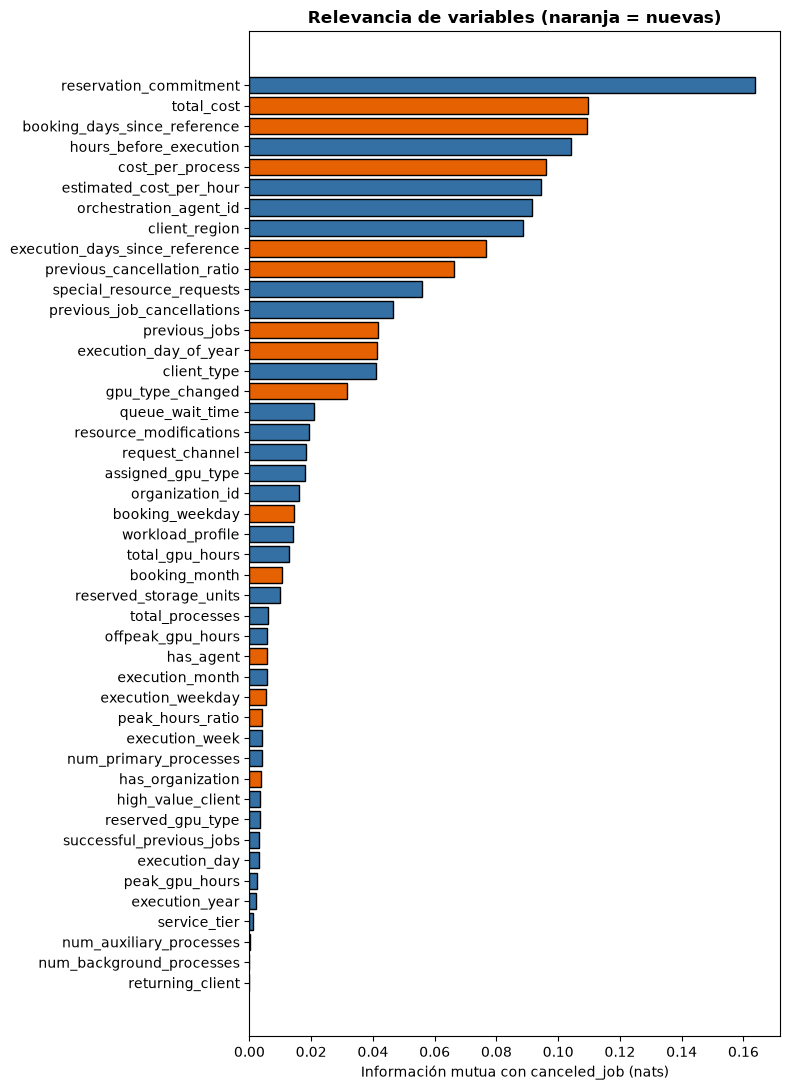

In [3]:
X_train_codes = X_train.copy()
for column in CATEGORICAL_FEATURES:
    X_train_codes[column] = X_train_codes[column].astype("category").cat.codes
X_train_codes = X_train_codes.fillna(-1)

mutual_information = pd.Series(
    mutual_info_classif(X_train_codes, y_train, discrete_features=[column in CATEGORICAL_FEATURES for column in X_train_codes.columns],
                        random_state=RANDOM_STATE),
    index=X_train_codes.columns,
).sort_values()

fig, ax = plt.subplots(figsize=(8, 11))
colors = ["#e66101" if column in engineered_columns else "#3470a3" for column in mutual_information.index]
ax.barh(mutual_information.index, mutual_information.values, color=colors, edgecolor="black")
ax.set_xlabel("Información mutua con canceled_job (nats)")
ax.set_title("Relevancia de variables (naranja = nuevas)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "07_mutual_information.png", dpi=300)
plt.show()

- Más relevantes: `reservation_commitment`, costo (`total_cost`, `cost_per_process`), fecha de reserva, antelación, agente y región.
- Varias variables nuevas quedan entre las más informativas.
- Se mantienen todas: los modelos de boosting eligen sus splits y la comparación del notebook 4 se hace con todas.

## 3.3 Exploración no supervisada: PCA + K-means

In [4]:
clustering_columns = ["hours_before_execution", "total_gpu_hours", "total_processes", "estimated_cost_per_hour",
                      "special_resource_requests", "resource_modifications", "previous_job_cancellations",
                      "queue_wait_time", "gpu_type_changed", "has_agent"]
X_scaled = StandardScaler().fit_transform(X_train[clustering_columns].fillna(0))

cluster_range = range(2, 11)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled).inertia_ for k in cluster_range]

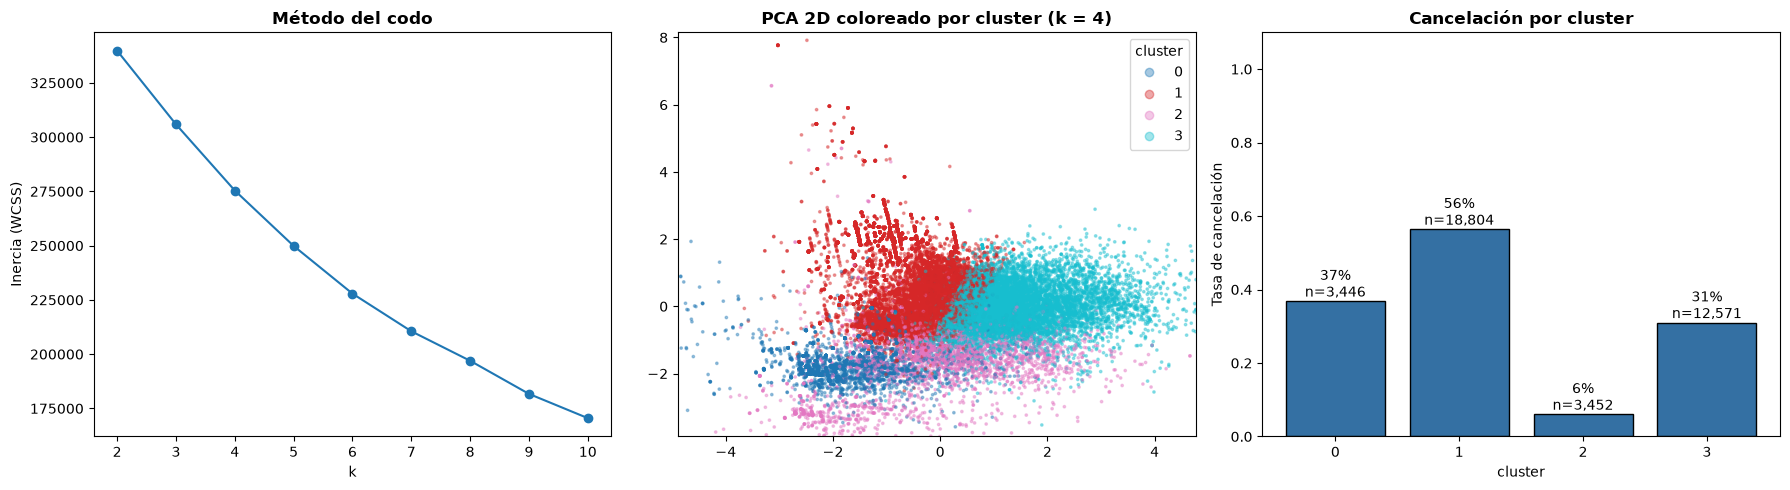

In [5]:
N_CLUSTERS = 4
cluster_labels = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
principal_components = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(list(cluster_range), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Método del codo", fontweight="bold")

scatter = axes[1].scatter(principal_components[:, 0], principal_components[:, 1], c=cluster_labels, cmap="tab10", s=3, alpha=0.4)
axes[1].set_xlim(np.percentile(principal_components[:, 0], [0.1, 99.9]))
axes[1].set_ylim(np.percentile(principal_components[:, 1], [0.1, 99.9]))
axes[1].legend(*scatter.legend_elements(), title="cluster")
axes[1].set_title(f"PCA 2D coloreado por cluster (k = {N_CLUSTERS})", fontweight="bold")

cluster_cancellation_rate = y_train.groupby(cluster_labels).agg(["mean", "size"])
bars = axes[2].bar(cluster_cancellation_rate.index.astype(str), cluster_cancellation_rate["mean"], color="#3470a3", edgecolor="black")
axes[2].bar_label(bars, labels=[f"{rate:.0%}\nn={int(size):,}" for rate, size in cluster_cancellation_rate.values])
axes[2].set_ylim(0, 1.1)
axes[2].set_xlabel("cluster")
axes[2].set_ylabel("Tasa de cancelación")
axes[2].set_title("Cancelación por cluster", fontweight="bold")
plt.tight_layout()
fig.savefig(FIGURES_PATH / "08_pca_kmeans.png", dpi=300)
plt.show()

- Los segmentos encontrados sin usar el target tienen tasas de cancelación muy distintas → hay estructura que los modelos supervisados pueden aprovechar.